# Análisis preliminar de variables para Machine Learning: tabla cancion

## 1. Carga y revisión inicial del dataset

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
from pathlib import Path

def carpeta_proyecto(nombre, marca):
    """Localiza los CSV en Jupyter, Visual Studio Code y Colab."""
    from pathlib import Path
    import json

    saltar = {
        ".config", "sample_data", "drive", ".git", "__pycache__",
        "node_modules", ".ipynb_checkpoints", "site-packages",
    }

    def directorio_notebook():
        try:
            return Path(__vsc_ipynb_file__).resolve().parent
        except NameError:
            pass
        try:
            from urllib.request import urlopen
            try:
                from ipykernel.connect import get_connection_file
            except ImportError:
                from ipykernel import get_connection_file
            conexion = Path(get_connection_file())
            kernel_id = conexion.name.replace("kernel-", "").replace(".json", "")
            servidores = list(conexion.parent.glob("jpserver-*.json"))[:3]
            for servidor in servidores:
                try:
                    info = json.loads(servidor.read_text(encoding="utf-8"))
                except (OSError, json.JSONDecodeError):
                    continue
                url = str(info.get("url", "")).rstrip("/")
                raiz = info.get("root_dir")
                if not url or not raiz:
                    continue
                api = url + "/api/sessions"
                token = info.get("token") or ""
                if token:
                    api += "?token=" + token
                try:
                    with urlopen(api, timeout=0.8) as respuesta:
                        sesiones = json.loads(respuesta.read().decode())
                except Exception:
                    continue
                for sesion in sesiones:
                    kid = (sesion.get("kernel") or {}).get("id")
                    if kid != kernel_id:
                        continue
                    cuaderno = sesion.get("notebook") or {}
                    relativo = cuaderno.get("path") or sesion.get("path")
                    if relativo:
                        return (Path(raiz) / relativo).resolve().parent
        except Exception:
            pass
        return None

    bases = []
    notebook = directorio_notebook()
    if notebook is not None:
        bases.append(notebook)
    bases.append(Path.cwd().resolve())
    content = Path("/content")
    if content.is_dir():
        bases.append(content)
        drive = content / "drive" / "MyDrive"
        if drive.is_dir():
            bases.append(drive)

    nombradas = []
    sueltas = []
    vistos = set()

    def considerar(directorio, aceptar_suelto):
        if directorio in vistos:
            return
        vistos.add(directorio)
        try:
            carpeta = directorio / nombre
            if (carpeta / marca).is_file():
                nombradas.append(carpeta)
                return
            if directorio.name == nombre and (directorio / marca).is_file():
                nombradas.append(directorio)
                return
            if aceptar_suelto and (directorio / marca).is_file():
                sueltas.append(directorio)
        except OSError:
            return

    def hijos(directorio, profundidad, limite):
        if profundidad < 0 or limite[0] <= 0 or not directorio.is_dir():
            return
        try:
            entradas = list(directorio.iterdir())
        except OSError:
            return
        for hijo in entradas:
            if not hijo.is_dir() or hijo.name.startswith(".") or hijo.name in saltar:
                continue
            limite[0] -= 1
            considerar(hijo, False)
            if nombradas or limite[0] <= 0:
                return
            hijos(hijo, profundidad - 1, limite)
            if nombradas or limite[0] <= 0:
                return

    for base in bases:
        considerar(base, True)
        if nombradas:
            break
        for padre in list(base.parents)[:6]:
            considerar(padre, False)
            if nombradas:
                break
        if nombradas:
            break
        profundidad = 3 if base.name in {"content", "MyDrive"} else 2
        hijos(base, profundidad, [400])
        if nombradas:
            break

    if nombradas:
        return nombradas[0]
    if sueltas:
        return sueltas[0]
    raise FileNotFoundError(
        "No se encuentra " + marca + ". "
        "Tiene que existir la carpeta '" + nombre + "' en el proyecto, "
        "o el archivo en el directorio de trabajo. En Colab puede estar junto a sample_data."
    )




ORIGINALES = carpeta_proyecto("datos originales", "cancion.csv")
print("Originales:", ORIGINALES)

df_cancion = pd.read_csv(ORIGINALES / "cancion.csv")
display(df_cancion.head())

,id_cancion,cancion,duracion,coste,id_genero,id_disco,id_autor,id_discografica
0,1,blues.00000.wav,138.0,744.01,1,1,1,1
1,2,blues.00001.wav,142.0,4178.85,1,2,2,2
2,3,blues.00002.wav,96.0,3226.40,1,3,4,3
3,4,blues.00003.wav,111.0,3618.77,1,4,6,4
4,5,blues.00004.wav,191.0,1990.81,1,5,7,5


In [ ]:
df_cancion_raw = df_cancion.copy()

In [ ]:
df_cancion_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id_cancion       1000 non-null   int64  
 1   cancion          1000 non-null   object 
 2   duracion         982 non-null    float64
 3   coste            1000 non-null   float64
 4   id_genero        1000 non-null   int64  
 5   id_disco         1000 non-null   int64  
 6   id_autor         1000 non-null   int64  
 7   id_discografica  1000 non-null   int64  
dtypes: float64(2), int64(5), object(1)
memory usage: 62.6+ KB


In [ ]:
# Dimensiones del DataFrame
print(f"Número de filas: {df_cancion.shape[0]}")
print(f"Número de columnas: {df_cancion.shape[1]}")

# Primer vistazo a la estructura
display(df_cancion.head())

# Información general de columnas y tipos de datos
df_cancion.info()


Número de filas: 1000
Número de columnas: 8


,id_cancion,cancion,duracion,coste,id_genero,id_disco,id_autor,id_discografica
0,1,blues.00000.wav,138.0,744.01,1,1,1,1
1,2,blues.00001.wav,142.0,4178.85,1,2,2,2
2,3,blues.00002.wav,96.0,3226.40,1,3,4,3
3,4,blues.00003.wav,111.0,3618.77,1,4,6,4
4,5,blues.00004.wav,191.0,1990.81,1,5,7,5


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id_cancion       1000 non-null   int64  
 1   cancion          1000 non-null   object 
 2   duracion         982 non-null    float64
 3   coste            1000 non-null   float64
 4   id_genero        1000 non-null   int64  
 5   id_disco         1000 non-null   int64  
 6   id_autor         1000 non-null   int64  
 7   id_discografica  1000 non-null   int64  
dtypes: float64(2), int64(5), object(1)
memory usage: 62.6+ KB


En primer lugar, se revisa la estructura general de la tabla de canciones para conocer el número de registros, las columnas disponibles y los tipos de datos. Este paso permite identificar qué variables podrían ser candidatas para el análisis preliminar orientado a Machine Learning y cuáles podrían requerir tratamiento previo.

In [ ]:
# Resumen inicial de las columnas disponibles
resumen_columnas = pd.DataFrame({
    'columna': df_cancion.columns,
    'tipo_dato': df_cancion.dtypes.values,
    'valores_nulos': df_cancion.isnull().sum().values,
    'valores_unicos': df_cancion.nunique().values
})

display(resumen_columnas)

,columna,tipo_dato,valores_nulos,valores_unicos
0,id_cancion,int64,0,1000
1,cancion,object,0,1000
2,duracion,float64,18,224
3,coste,float64,0,999
4,id_genero,int64,0,10
5,id_disco,int64,0,200
6,id_autor,int64,0,322
7,id_discografica,int64,0,32


Se genera un resumen de las columnas disponibles en la tabla de canciones, incluyendo el tipo de dato, el número de valores nulos y la cantidad de valores únicos por variable. Este análisis preliminar permite diferenciar entre variables identificadoras, variables categóricas, variables numéricas y la variable objetivo del modelo.



### Clasificación preliminar de variables para el análisis

Se revisan las columnas disponibles en la tabla de canciones para identificar el papel que puede tener cada variable dentro del análisis previo a Machine Learning. En esta fase no se descarta ninguna variable de forma definitiva, sino que se documentan sus características, incidencias y posibles relaciones con `id_genero`.

| Variable | Tipo de variable | Papel en el análisis | Observación |
|---|---|---|---|
| `id_genero` | Categórica codificada | Variable objetivo | Representa el género musical codificado que se desea predecir. |
| `id_cancion` | Identificador | Variable a documentar | Identifica cada canción dentro del dataset. Se analiza su comportamiento, aunque su interpretación debe hacerse con cautela. |
| `cancion` | Texto / nombre de canción | Variable a documentar | Identifica el nombre o referencia de la canción. Al ser texto, no se incluye directamente en correlaciones numéricas. |
| `duracion` | Numérica | Variable numérica de análisis | Puede aportar información temporal sobre la canción. Presenta valores nulos y una duración igual a 0. |
| `coste` | Numérica | Variable numérica de análisis | Presenta valores negativos y posibles valores atípicos, por lo que se documenta su comportamiento. |
| `id_disco` | Categórica codificada | Variable categórica de análisis | Puede estar relacionada con el género y se analiza frente a la variable objetivo. |
| `id_autor` | Categórica codificada | Variable categórica de análisis | Puede estar relacionada con el género y se analiza frente a la variable objetivo. |
| `id_discografica` | Categórica codificada | Variable categórica de análisis | Se analiza su relación con el género y con el resto de variables codificadas. |

Esta clasificación es preliminar. En esta fase no se seleccionan las variables definitivas del modelo, sino que se identifican aquellas que podrían ser útiles.
La variable `id_genero` se utilizará como variable objetivo, ya que representa el género musical codificado.

## 2. Identificación de la variable objetivo

In [ ]:
# Distribución de canciones por género codificado
distribucion_genero = (
    df_cancion['id_genero']
    .value_counts()
    .sort_index()
    .reset_index()
)

distribucion_genero.columns = ['id_genero', 'num_canciones']

display(distribucion_genero)

,id_genero,num_canciones
0,1,100
1,2,100
2,3,100
3,4,100
4,5,100
5,6,100
6,7,100
7,8,100
8,9,100
9,10,100


La variable objetivo `id_genero` presenta una distribución equilibrada: existen 10 clases de género musical y cada una contiene 100 canciones.

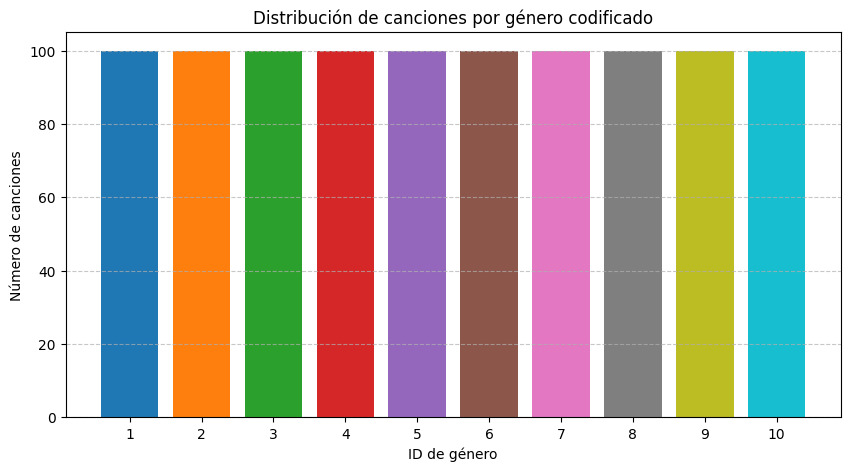

In [ ]:
import matplotlib.pyplot as plt

colores = plt.cm.tab10.colors[:len(distribucion_genero)]

plt.figure(figsize=(10, 5))

plt.bar(
    distribucion_genero['id_genero'].astype(str),
    distribucion_genero['num_canciones'],
    color=colores
)

plt.title('Distribución de canciones por género codificado')
plt.xlabel('ID de género')
plt.ylabel('Número de canciones')
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.show()

## 3. Revisión de calidad del dato

In [ ]:
# Revisión de valores nulos por variable
nulos_cancion = df_cancion.isnull().sum().reset_index()

nulos_cancion.columns = ['variable', 'num_nulos']

nulos_cancion['porcentaje_nulos'] = (
    nulos_cancion['num_nulos'] / len(df_cancion) * 100
).round(2)

display(nulos_cancion)

,variable,num_nulos,porcentaje_nulos
0,id_cancion,0,0.0
1,cancion,0,0.0
2,duracion,18,1.8
3,coste,0,0.0
4,id_genero,0,0.0
5,id_disco,0,0.0
6,id_autor,0,0.0
7,id_discografica,0,0.0


Se revisan los valores nulos presentes en la tabla de canciones. Esta comprobación es necesaria ya que es posible que algunos modelos no acepten valores nulos para trabajar.

En este caso, la variable `duracion` presenta valores nulos.



Este análisis se centrará en las variables disponibles en la tabla de canciones que pueden aportar información para predecir `id_genero`, especialmente `coste`, `duracion`, `id_disco`, `id_autor` , `id_discografica`, `cancion` e `id_cancion`

Siguiendo el criterio indicado, este análisis se realiza sobre los datos en bruto. Por tanto, no se corrigen en este notebook los valores nulos, negativos o atípicos detectados.


## 4. Descripción general de variables de análisis

In [ ]:
# Revisión del número de valores únicos de variables categóricas codificadas
variables_categoricas = ['id_disco', 'id_autor', 'id_discografica']

valores_unicos = pd.DataFrame({
    'variable': variables_categoricas,
    'valores_unicos': [df_cancion[col].nunique() for col in variables_categoricas],
    'porcentaje_sobre_total': [
        round(df_cancion[col].nunique() / len(df_cancion) * 100, 2)
        for col in variables_categoricas
    ]
})

display(valores_unicos)

,variable,valores_unicos,porcentaje_sobre_total
0,id_disco,200,20.0
1,id_autor,322,32.2
2,id_discografica,32,3.2


Se analiza el número de valores únicos de las variables categóricas codificadas, es decir, el número de valores distintos que presenta cada una. Esta revisión es importante antes de utilizar estas variables en Machine Learning, ya que un número de valores únicos muy alto puede provocar que el modelo aprenda asociaciones demasiado específicas del dataset en lugar de patrones generalizables.

In [ ]:
variables_analisis = ['coste','duracion', 'id_disco', 'id_autor', 'id_discografica']

display(df_cancion[variables_analisis].describe(include='all'))

,coste,duracion,id_disco,id_autor,id_discografica
count,1000.000000,982.000000,1000.00000,1000.000000,1000.00000
mean,2998.773210,155.886965,99.46000,160.970000,15.58100
std,1511.243043,112.802501,57.50159,93.970589,9.45679
min,-1755.660000,0.000000,1.00000,1.000000,1.00000
25%,2048.372500,110.000000,49.00000,76.000000,7.00000
50%,2991.770000,143.000000,100.50000,159.000000,15.00000
75%,3988.782500,173.750000,149.00000,243.000000,24.00000
max,7331.900000,817.000000,200.00000,326.000000,32.00000


La revisión de número de valores únicos muestra diferencias importantes entre las variables categóricas codificadas. `id_discografica` presenta un número de valores únicos moderado, con 32 valores únicos sobre 1000 canciones.
En cambio, `id_disco` e `id_autor` presentan un número de valores únicos más elevado.

## 5. Análisis de variables numéricas: duración y coste

### 5.1 Análisis de duración

In [ ]:
# Comprobación de duraciones negativas o iguales a cero
duraciones_invalidas = df_cancion[df_cancion['duracion'] <= 0]

print(f"Número de duraciones menores o iguales a cero: {len(duraciones_invalidas)}")
display(duraciones_invalidas)

Número de duraciones menores o iguales a cero: 1


,id_cancion,cancion,duracion,coste,id_genero,id_disco,id_autor,id_discografica
499,500,hiphop.00099.wav,0.0,2835.31,5,89,155,20


In [ ]:
# Resumen de duración por género codificado
duracion_por_genero = (
    df_cancion
    .groupby('id_genero')['duracion']
    .agg(['count', 'mean', 'median', 'min', 'max'])
    .round(2)
)

display(duracion_por_genero)

,count,mean,median,min,max
id_genero,,,,,
1,98,151.46,145.0,3.0,811.0
2,98,154.99,138.0,3.0,817.0
3,97,158.32,147.0,19.0,812.0
4,99,143.56,149.0,2.0,288.0
5,99,143.70,134.0,0.0,813.0
6,99,150.29,137.0,5.0,813.0
7,99,171.87,142.0,2.0,814.0
8,97,166.62,144.0,2.0,817.0
9,100,164.57,146.0,3.0,808.0


In [ ]:
# Análisis descriptivo de la variable duración
display(df_cancion['duracion'].describe())

,duracion
count,982.000000
mean,155.886965
std,112.802501
min,0.000000
25%,110.000000
50%,143.000000
75%,173.750000
max,817.000000


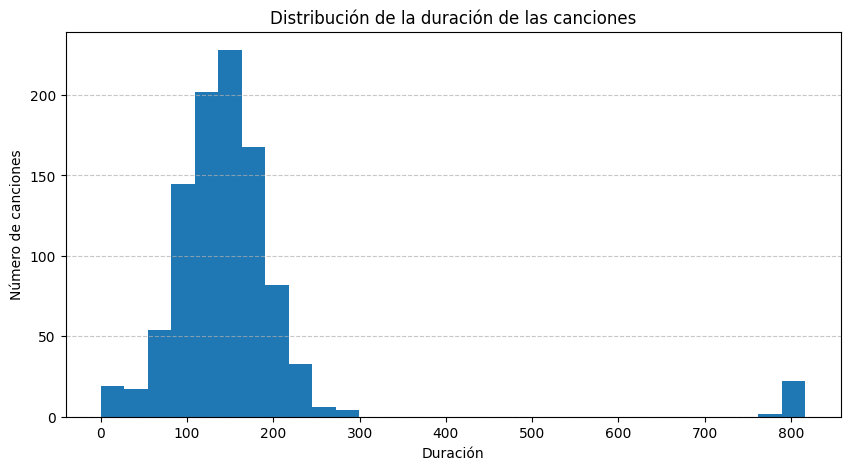

In [ ]:
plt.figure(figsize=(10, 5))

plt.hist(
    df_cancion['duracion'].dropna(),
    bins=30
)

plt.title('Distribución de la duración de las canciones')
plt.xlabel('Duración')
plt.ylabel('Número de canciones')
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.show()

El histograma permite observar la distribución de la variable `duracion` en el conjunto de canciones. Para la visualización se omiten únicamente los valores nulos, ya que no pueden representarse en el gráfico. El análisis se mantiene sobre los datos originales, sin corregir la duración igual a 0 detectada previamente.

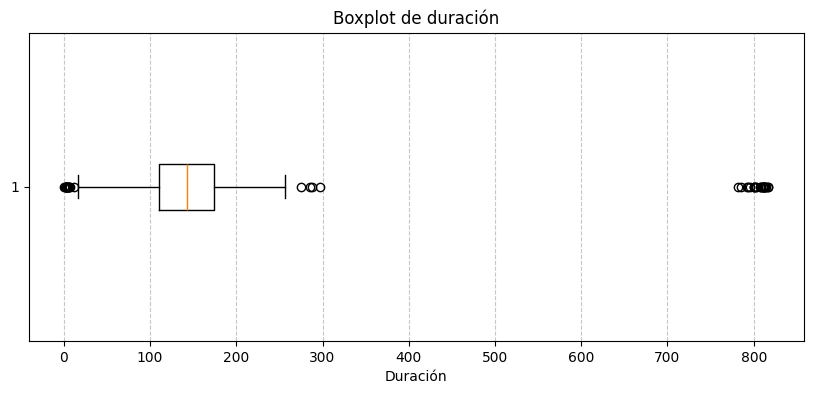

In [ ]:
plt.figure(figsize=(10, 4))

plt.boxplot(
    df_cancion['duracion'].dropna(),
    vert=False
)

plt.title('Boxplot de duración')
plt.xlabel('Duración')
plt.grid(axis='x', linestyle='--', alpha=0.7)

plt.show()

In [ ]:
df_cancion[df_cancion['duracion'] > 700].sort_values('duracion', ascending=False)

,id_cancion,cancion,duracion,coste,id_genero,id_disco,id_autor,id_discografica
120,121,classical.00020.wav,817.0,2782.88,2,27,54,32
714,715,pop.00014.wav,817.0,4039.61,8,151,238,6
645,646,metal.00045.wav,814.0,1739.18,7,138,230,10
577,578,jazz.00077.wav,813.0,787.96,6,116,180,4
456,457,hiphop.00056.wav,813.0,1624.66,5,99,138,26
911,912,rock.00011.wav,813.0,2735.29,10,190,300,11
246,247,country.00046.wav,812.0,3883.32,3,57,90,19
35,36,blues.00035.wav,811.0,3619.63,1,19,28,11
711,712,pop.00011.wav,811.0,-463.11,8,150,241,15
591,592,jazz.00091.wav,811.0,3197.01,6,106,178,10


El boxplot permite visualizar la dispersión de la variable `duracion` y detectar posibles valores atípicos. En este caso se omiten únicamente los valores nulos para poder representar el gráfico, pero no se modifica el DataFrame original.

Este análisis ayuda a comprobar si existen canciones con duraciones muy alejadas del resto.
En el boxplot de `duracion` se observan varios valores alejados del rango principal de la distribución.

In [ ]:
# Cálculo de outliers en duración mediante el método IQR

Q1_duracion = df_cancion['duracion'].quantile(0.25)
Q3_duracion = df_cancion['duracion'].quantile(0.75)
IQR_duracion = Q3_duracion - Q1_duracion

limite_inferior_duracion = Q1_duracion - 1.5 * IQR_duracion
limite_superior_duracion = Q3_duracion + 1.5 * IQR_duracion

outliers_duracion = df_cancion[
    (df_cancion['duracion'] < limite_inferior_duracion) |
    (df_cancion['duracion'] > limite_superior_duracion)
]

print(f"Límite inferior duración: {limite_inferior_duracion:.2f}")
print(f"Límite superior duración: {limite_superior_duracion:.2f}")
print(f"Número de outliers en duración: {len(outliers_duracion)}")
print(f"Porcentaje de outliers en duración: {(len(outliers_duracion) / len(df_cancion)) * 100:.2f}%")

display(outliers_duracion.sort_values('duracion', ascending=False))

Límite inferior duración: 14.38
Límite superior duración: 269.38
Número de outliers en duración: 44
Porcentaje de outliers en duración: 4.40%


,id_cancion,cancion,duracion,coste,id_genero,id_disco,id_autor,id_discografica
120,121,classical.00020.wav,817.0,2782.88,2,27,54,32
714,715,pop.00014.wav,817.0,4039.61,8,151,238,6
645,646,metal.00045.wav,814.0,1739.18,7,138,230,10
577,578,jazz.00077.wav,813.0,787.96,6,116,180,4
456,457,hiphop.00056.wav,813.0,1624.66,5,99,138,26
911,912,rock.00011.wav,813.0,2735.29,10,190,300,11
246,247,country.00046.wav,812.0,3883.32,3,57,90,19
711,712,pop.00011.wav,811.0,-463.11,8,150,241,15
591,592,jazz.00091.wav,811.0,3197.01,6,106,178,10
625,626,metal.00025.wav,811.0,3918.29,7,134,223,20


Se calcula el número de posibles valores atípicos en la variable `duracion` mediante el IQR. Son 44 los valores atípicos


Se analiza la variable `duracion`, que ya se encuentra expresada en segundos. Primero se revisan posibles valores inválidos, como duraciones iguales o inferiores a 0, y posteriormente se calcula un resumen estadístico por `id_genero`.

El objetivo es comprobar si existen diferencias relevantes de duración entre géneros que puedan convertir esta variable en una candidata útil para el modelo de Machine Learning.



### 5.2 Análisis de coste

In [ ]:
costes_negativos = df_cancion[df_cancion['coste'] < 0]

print(f"Número de registros con coste negativo: {len(costes_negativos)}")
print(f"Porcentaje de costes negativos: {(len(costes_negativos) / len(df_cancion)) * 100:.2f}%")

display(costes_negativos)

Número de registros con coste negativo: 26
Porcentaje de costes negativos: 2.60%


,id_cancion,cancion,duracion,coste,id_genero,id_disco,id_autor,id_discografica
61,62,blues.00061.wav,227.0,-75.24,1,19,19,22
68,69,blues.00068.wav,110.0,-162.14,1,7,18,9
82,83,blues.00082.wav,219.0,-315.93,1,17,3,4
193,194,classical.00093.wav,123.0,-590.15,2,27,56,15
195,196,classical.00095.wav,67.0,-946.54,2,23,65,3
239,240,country.00039.wav,285.0,-70.79,3,43,89,16
260,261,country.00060.wav,133.0,-884.22,3,53,73,18
292,293,country.00092.wav,64.0,-618.03,3,49,96,8
357,358,disco.00057.wav,150.0,-169.82,4,75,127,3
366,367,disco.00066.wav,NaN,-561.33,4,69,100,14


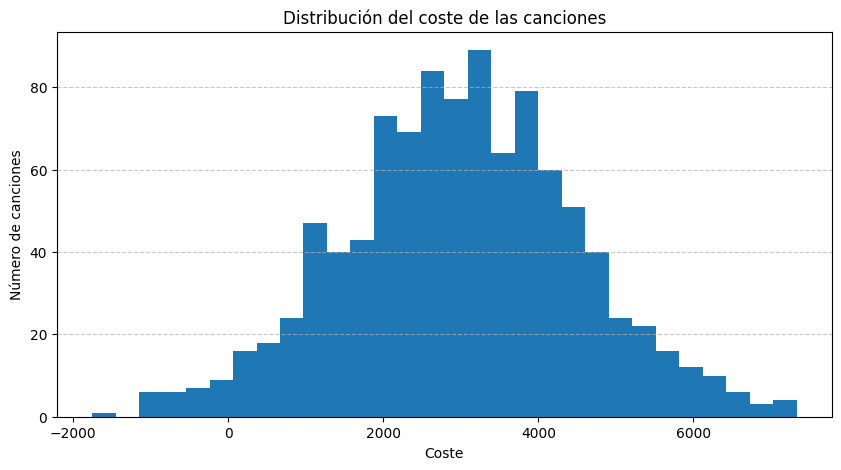

In [ ]:
plt.figure(figsize=(10, 5))

plt.hist(
    df_cancion['coste'].dropna(),
    bins=30
)

plt.title('Distribución del coste de las canciones')
plt.xlabel('Coste')
plt.ylabel('Número de canciones')
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.show()



La variable `coste` presenta una distribución aproximadamente centrada entre los 2.000 y 4.000, donde se concentra la mayor parte de las canciones. También se observan valores en los extremos, tanto por debajo de 0 como por encima de 6.000.


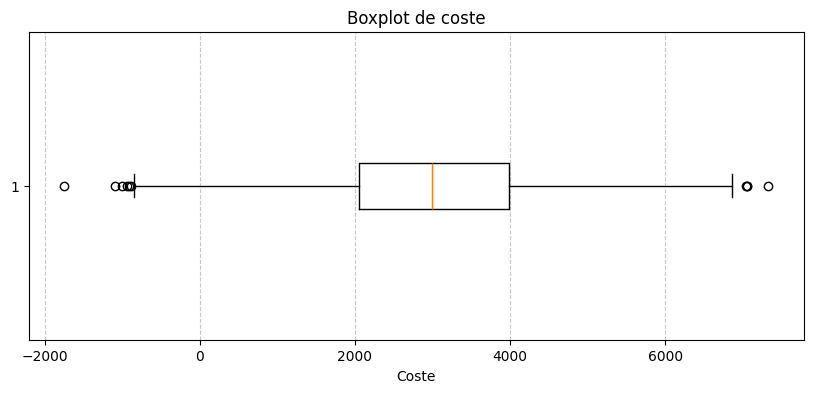

In [ ]:
plt.figure(figsize=(10, 4))

plt.boxplot(
    df_cancion['coste'].dropna(),
    vert=False
)

plt.title('Boxplot de coste')
plt.xlabel('Coste')
plt.grid(axis='x', linestyle='--', alpha=0.7)

plt.show()

El boxplot de `coste` muestra una mediana cercana a los 3.000.

In [ ]:
# Cálculo de outliers en coste mediante el método IQR

Q1_coste = df_cancion['coste'].quantile(0.25)
Q3_coste = df_cancion['coste'].quantile(0.75)
IQR_coste = Q3_coste - Q1_coste

limite_inferior_coste = Q1_coste - 1.5 * IQR_coste
limite_superior_coste = Q3_coste + 1.5 * IQR_coste

outliers_coste = df_cancion[
    (df_cancion['coste'] < limite_inferior_coste) |
    (df_cancion['coste'] > limite_superior_coste)
]

print(f"Límite inferior coste: {limite_inferior_coste:.2f}")
print(f"Límite superior coste: {limite_superior_coste:.2f}")
print(f"Número de outliers en coste: {len(outliers_coste)}")
print(f"Porcentaje de outliers en coste: {(len(outliers_coste) / len(df_cancion)) * 100:.2f}%")

display(outliers_coste.sort_values('coste'))

Límite inferior coste: -862.24
Límite superior coste: 6899.40
Número de outliers en coste: 10
Porcentaje de outliers en coste: 1.00%


,id_cancion,cancion,duracion,coste,id_genero,id_disco,id_autor,id_discografica
720,721,pop.00020.wav,226.0,-1755.66,8,151,249,16
412,413,hiphop.00012.wav,102.0,-1099.03,5,89,148,25
604,605,metal.00004.wav,220.0,-1008.08,7,124,207,6
195,196,classical.00095.wav,67.0,-946.54,2,23,65,3
407,408,hiphop.00007.wav,166.0,-918.44,5,87,134,3
260,261,country.00060.wav,133.0,-884.22,3,53,73,18
144,145,classical.00044.wav,145.0,7037.70,2,31,58,10
259,260,country.00059.wav,182.0,7049.92,3,57,79,22
178,179,classical.00078.wav,108.0,7050.61,2,29,37,28
665,666,metal.00065.wav,156.0,7331.90,7,140,211,25


Se detectan 10 outliers, lo que representa únicamente el 1,00% del total del dataset. Por tanto, aunque existen valores extremos, su presencia es reducida en comparación con el conjunto completo de canciones.


### 5.3 Comparación de duración y coste por género

In [ ]:
resumen_genero_numericas = (
    df_cancion
    .groupby('id_genero')
    .agg(
        media_duracion=('duracion', 'mean'),
        mediana_duracion=('duracion', 'median'),
        media_coste=('coste', 'mean'),
        mediana_coste=('coste', 'median')
    )
    .round(2)
)

display(resumen_genero_numericas)

,media_duracion,mediana_duracion,media_coste,mediana_coste
id_genero,,,,
1,151.46,145.0,3091.00,3178.96
2,154.99,138.0,3026.03,2996.04
3,158.32,147.0,2911.62,2840.38
4,143.56,149.0,2996.64,3192.44
5,143.70,134.0,3174.77,3174.40
6,150.29,137.0,2981.60,3111.94
7,171.87,142.0,3007.76,3029.59
8,166.62,144.0,2929.47,2909.33
9,164.57,146.0,2934.16,2922.02


La comparación por `id_genero` muestra que la duración media varía ligeramente entre géneros, aunque las medianas son bastante similares. El género 7 presenta la mayor duración media, mientras que los géneros 4 y 5 muestran las medias más bajas.

En cuanto al `coste`, los valores medios y medianos se mantienen bastante próximos entre géneros, generalmente alrededor de los 2.900-3.200. No se observa una diferencia clara entre géneros que permita identificar un patrón fuerte solo con esta variable.

Por tanto, `duracion` y `coste` podrían aportar información al modelo, pero de forma limitada. Ninguna de las dos variables parece separar claramente los géneros por sí sola, por lo que deberían combinarse con otras variables al usarlas en Machine Learning.

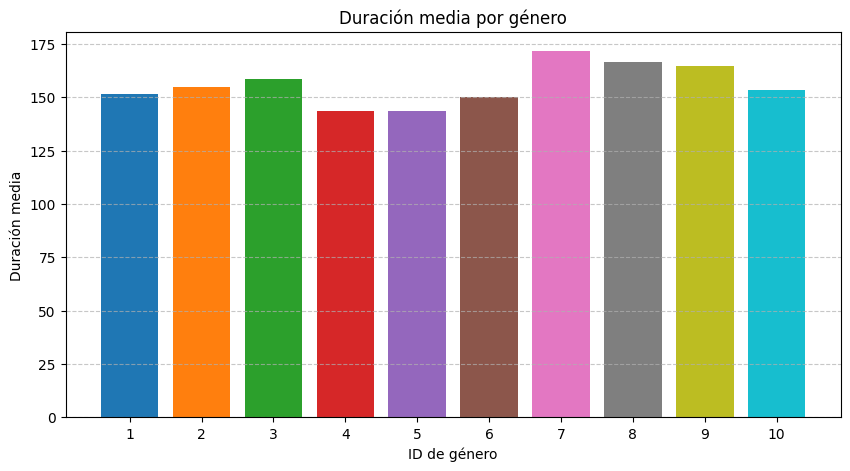

In [ ]:
colores = plt.cm.tab10.colors[:len(resumen_genero_numericas)]

plt.figure(figsize=(10, 5))

plt.bar(
    resumen_genero_numericas.index.astype(str),
    resumen_genero_numericas['media_duracion'],
    color=colores
)

plt.title('Duración media por género')
plt.xlabel('ID de género')
plt.ylabel('Duración media')
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.show()

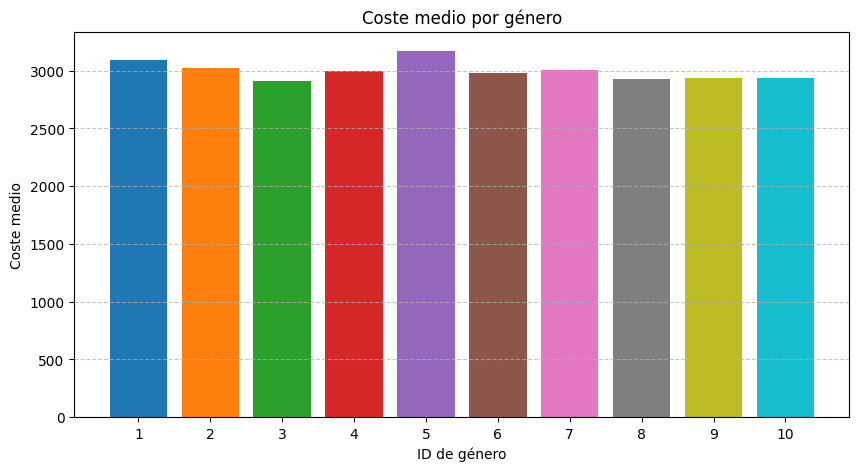

In [ ]:
colores = plt.cm.tab10.colors[:len(resumen_genero_numericas)]

plt.figure(figsize=(10, 5))

plt.bar(
    resumen_genero_numericas.index.astype(str),
    resumen_genero_numericas['media_coste'],
    color=colores
)

plt.title('Coste medio por género')
plt.xlabel('ID de género')
plt.ylabel('Coste medio')
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.show()

### 5.4 Relación entre duración y coste

In [ ]:
correlacion_duracion_coste = df_cancion[['duracion', 'coste']].corr()

display(correlacion_duracion_coste)

,duracion,coste
duracion,1.000000,-0.032302
coste,-0.032302,1.000000


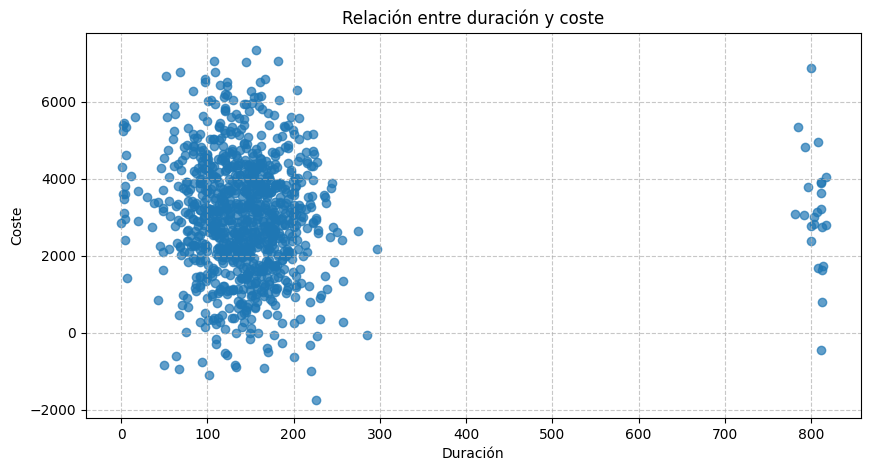

In [ ]:
plt.figure(figsize=(10, 5))

plt.scatter(
    df_cancion['duracion'],
    df_cancion['coste'],
    alpha=0.7
)

plt.title('Relación entre duración y coste')
plt.xlabel('Duración')
plt.ylabel('Coste')
plt.grid(True, linestyle='--', alpha=0.7)

plt.show()


La correlación entre `duracion` y `coste` es de -0,032, un valor muy próximo a 0. Esto indica que no existe una relación lineal significativa entre ambas variables.

El gráfico de dispersión confirma esta idea: la mayoría de canciones se concentra en duraciones entre 100 y 200 segundos, pero dentro de ese rango los costes varían mucho, sin seguir una tendencia clara.

## 6. Análisis de variables textuales, identificadoras y categóricas



### 6.1 Análisis de la variable cancion

In [ ]:
# Análisis de la variable 'cancion' frente al género

cancion_genero = (
    df_cancion
    .groupby('cancion', dropna=False)
    .agg(
        num_canciones=('id_cancion', 'count'),
        generos_distintos=('id_genero', 'nunique'),
        generos=('id_genero', lambda x: sorted(x.unique()))
    )
    .sort_values(['generos_distintos', 'num_canciones'], ascending=[False, False])
)

total_registros = len(df_cancion)
nombres_distintos = df_cancion['cancion'].nunique(dropna=False)
nombres_repetidos = (cancion_genero['num_canciones'] > 1).sum()
nombres_un_genero = (cancion_genero['generos_distintos'] == 1).sum()
nombres_varios_generos = (cancion_genero['generos_distintos'] > 1).sum()
porcentaje_un_genero = (nombres_un_genero / nombres_distintos) * 100

print(f"Número total de registros: {total_registros}")
print(f"Número de nombres de canción distintos: {nombres_distintos}")
print(f"Número de nombres de canción repetidos: {nombres_repetidos}")
print(f"Número de nombres asociados a un único género: {nombres_un_genero}")
print(f"Número de nombres asociados a varios géneros: {nombres_varios_generos}")
print(f"Porcentaje de nombres asociados a un único género: {porcentaje_un_genero:.2f}%")

display(cancion_genero.head(20))

Número total de registros: 1000
Número de nombres de canción distintos: 1000
Número de nombres de canción repetidos: 0
Número de nombres asociados a un único género: 1000
Número de nombres asociados a varios géneros: 0
Porcentaje de nombres asociados a un único género: 100.00%


,num_canciones,generos_distintos,generos
cancion,,,
blues.00000.wav,1,1,[1]
blues.00001.wav,1,1,[1]
blues.00002.wav,1,1,[1]
blues.00003.wav,1,1,[1]
blues.00004.wav,1,1,[1]
blues.00005.wav,1,1,[1]
blues.00006.wav,1,1,[1]
blues.00007.wav,1,1,[1]
blues.00008.wav,1,1,[1]


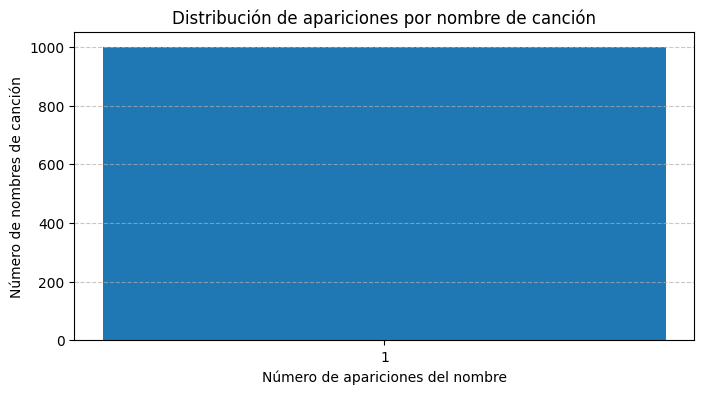

In [ ]:
conteo_nombres_cancion = (
    cancion_genero['num_canciones']
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(8, 4))

plt.bar(
    conteo_nombres_cancion.index.astype(str),
    conteo_nombres_cancion.values
)

plt.title('Distribución de apariciones por nombre de canción')
plt.xlabel('Número de apariciones del nombre')
plt.ylabel('Número de nombres de canción')
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.show()

La variable `cancion` contiene el nombre de la canción, por lo que no se incluye directamente en la matriz de correlación numérica. Sin embargo, se analiza como variable textual para comprobar si existen nombres repetidos y si una misma canción aparece asociada a uno o varios géneros.



### 6.2 Análisis de la variable id_cancion

In [ ]:
# Análisis de la variable 'id_cancion' frente al género

id_cancion_genero = (
    df_cancion
    .groupby('id_cancion', dropna=False)
    .agg(
        num_registros=('id_cancion', 'count'),
        generos_distintos=('id_genero', 'nunique'),
        generos=('id_genero', lambda x: sorted(x.unique()))
    )
    .sort_values(['generos_distintos', 'num_registros'], ascending=[False, False])
)

total_registros = len(df_cancion)
ids_distintos = df_cancion['id_cancion'].nunique(dropna=False)
ids_repetidos = (id_cancion_genero['num_registros'] > 1).sum()
ids_un_genero = (id_cancion_genero['generos_distintos'] == 1).sum()
ids_varios_generos = (id_cancion_genero['generos_distintos'] > 1).sum()
porcentaje_un_genero = (ids_un_genero / ids_distintos) * 100

print(f"Número total de registros: {total_registros}")
print(f"Número de id_cancion distintos: {ids_distintos}")
print(f"Número de id_cancion repetidos: {ids_repetidos}")
print(f"Número de id_cancion asociados a un único género: {ids_un_genero}")
print(f"Número de id_cancion asociados a varios géneros: {ids_varios_generos}")
print(f"Porcentaje de id_cancion asociados a un único género: {porcentaje_un_genero:.2f}%")

display(id_cancion_genero.head(20))

Número total de registros: 1000
Número de id_cancion distintos: 1000
Número de id_cancion repetidos: 0
Número de id_cancion asociados a un único género: 1000
Número de id_cancion asociados a varios géneros: 0
Porcentaje de id_cancion asociados a un único género: 100.00%


,num_registros,generos_distintos,generos
id_cancion,,,
1,1,1,[1]
2,1,1,[1]
3,1,1,[1]
4,1,1,[1]
5,1,1,[1]
6,1,1,[1]
7,1,1,[1]
8,1,1,[1]
9,1,1,[1]


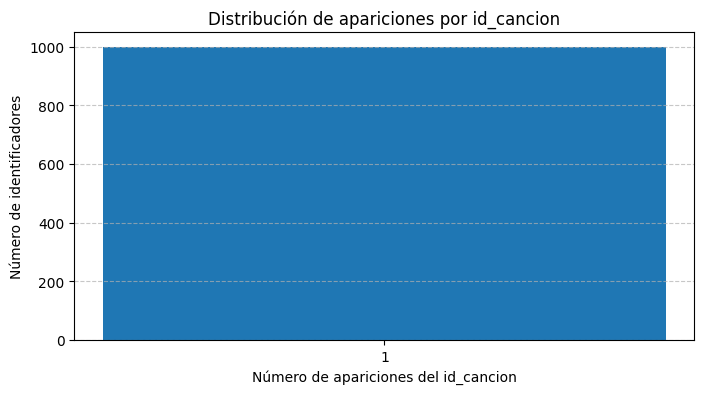

In [ ]:
conteo_ids_cancion = (
    id_cancion_genero['num_registros']
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(8, 4))

plt.bar(
    conteo_ids_cancion.index.astype(str),
    conteo_ids_cancion.values
)

plt.title('Distribución de apariciones por id_cancion')
plt.xlabel('Número de apariciones del id_cancion')
plt.ylabel('Número de identificadores')
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.show()



La variable `id_cancion` funciona como identificador de cada canción dentro del dataset. Su análisis permite comprobar si existen identificadores repetidos y si alguno aparece asociado a más de un género.


In [ ]:
# Distribución de id_cancion por género

id_canciones_por_genero = (
    df_cancion
    .groupby('id_genero')['id_cancion']
    .nunique()
    .reset_index(name='num_id_cancion')
)

display(id_canciones_por_genero)

,id_genero,num_id_cancion
0,1,100
1,2,100
2,3,100
3,4,100
4,5,100
5,6,100
6,7,100
7,8,100
8,9,100
9,10,100


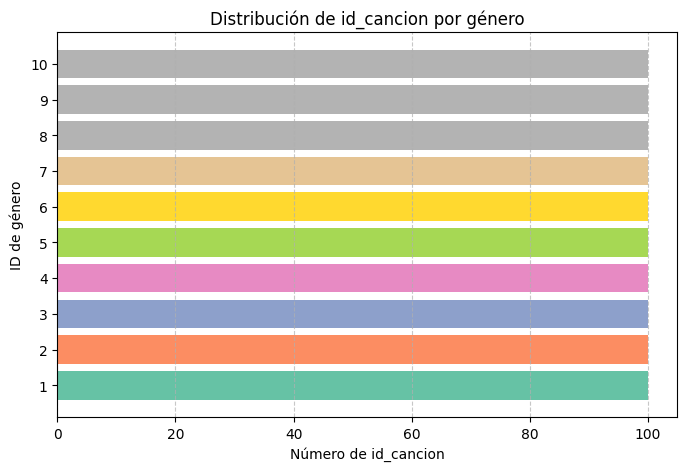

In [ ]:
colores = plt.cm.Set2(range(len(id_canciones_por_genero)))

plt.figure(figsize=(8, 5))

plt.barh(
    id_canciones_por_genero['id_genero'].astype(str),
    id_canciones_por_genero['num_id_cancion'],
    color=colores
)

plt.title('Distribución de id_cancion por género')
plt.xlabel('Número de id_cancion')
plt.ylabel('ID de género')
plt.grid(axis='x', linestyle='--', alpha=0.7)

plt.show()

### 6.3 Resumen general de variables frente a id_genero

In [ ]:
# Análisis de todas las variables frente al género

variables_analisis_genero = [
    col for col in df_cancion.columns
    if col != 'id_genero'
]

resumen_variables_genero = []

for variable in variables_analisis_genero:
    agrupacion = (
        df_cancion
        .groupby(variable, dropna=False)
        .agg(
            num_canciones=('id_cancion', 'count'),
            generos_distintos=('id_genero', 'nunique')
        )
    )

    resumen_variables_genero.append({
        'variable': variable,
        'valores_unicos': df_cancion[variable].nunique(dropna=False),
        'media_canciones_por_valor': round(agrupacion['num_canciones'].mean(), 2),
        'valores_con_1_cancion': (agrupacion['num_canciones'] == 1).sum(),
        'valores_asociados_a_1_genero': (agrupacion['generos_distintos'] == 1).sum()
    })

resumen_variables_genero = pd.DataFrame(resumen_variables_genero)

display(resumen_variables_genero)

,variable,valores_unicos,media_canciones_por_valor,valores_con_1_cancion,valores_asociados_a_1_genero
0,id_cancion,1000,1.00,1000,1000
1,cancion,1000,1.00,1000,1000
2,duracion,225,4.44,55,58
3,coste,999,1.00,998,998
4,id_disco,200,5.00,6,200
5,id_autor,322,3.11,48,316
6,id_discografica,32,31.25,0,0


Esta tabla resume cómo se comporta cada variable respecto a `id_genero`. Para cada variable se calcula cuántos valores distintos tiene, cuántas canciones aparecen de media por cada valor, cuántos valores aparecen una sola vez y cuántos están asociados a un único género.

### 6.4 Análisis de la variable id_disco

In [ ]:
discos_generos = (
    df_cancion
    .groupby('id_disco')
    .agg(
        num_canciones=('id_cancion', 'count'),
        generos_distintos=('id_genero', 'nunique'),
        generos=('id_genero', lambda x: sorted(x.unique()))
    )
    .sort_values('generos_distintos', ascending=False)
)

display(discos_generos.head(20))

,num_canciones,generos_distintos,generos
id_disco,,,
1,5,1,[1]
2,10,1,[1]
3,5,1,[1]
4,2,1,[1]
5,1,1,[1]
6,5,1,[1]
7,7,1,[1]
8,6,1,[1]
9,6,1,[1]


In [ ]:
discos_por_genero = (
    df_cancion
    .groupby('id_genero')['id_disco']
    .nunique()
    .reset_index(name='num_discos')
)

display(discos_por_genero)

,id_genero,num_discos
0,1,20
1,2,20
2,3,20
3,4,20
4,5,20
5,6,20
6,7,20
7,8,20
8,9,20
9,10,20


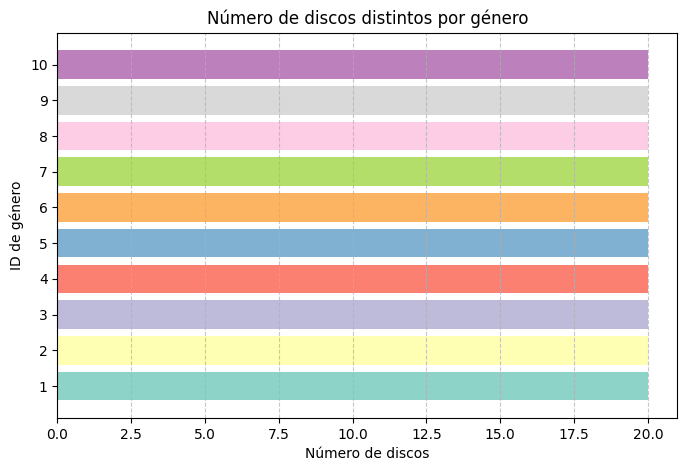

In [ ]:
# Número de discos distintos por género

discos_por_genero = (
    df_cancion
    .groupby('id_genero')['id_disco']
    .nunique()
    .reset_index(name='num_discos')
    .sort_values('num_discos')
)

colores = plt.cm.Set3(range(len(discos_por_genero)))

plt.figure(figsize=(8, 5))

plt.barh(
    discos_por_genero['id_genero'].astype(str),
    discos_por_genero['num_discos'],
    color=colores
)

plt.title('Número de discos distintos por género')
plt.xlabel('Número de discos')
plt.ylabel('ID de género')
plt.grid(axis='x', linestyle='--', alpha=0.7)

plt.show()

### 6.5 Análisis de la variable id_autor

In [ ]:
autores_generos = (
    df_cancion
    .groupby('id_autor')
    .agg(
        num_canciones=('id_cancion', 'count'),
        generos_distintos=('id_genero', 'nunique'),
        generos=('id_genero', lambda x: sorted(x.unique()))
    )
    .sort_values(['generos_distintos', 'num_canciones'], ascending=[False, False])
)

display(autores_generos.head(20))

,num_canciones,generos_distintos,generos
id_autor,,,
25,10,2,"[1, 10]"
136,8,2,"[5, 8]"
134,6,2,"[5, 8]"
147,5,2,"[5, 8]"
32,4,2,"[1, 10]"
141,4,2,"[5, 8]"
72,9,1,[3]
204,8,1,[7]
135,7,1,[5]


In [ ]:
autores_un_genero = (autores_generos['generos_distintos'] == 1).sum()
autores_varios_generos = (autores_generos['generos_distintos'] > 1).sum()

print(f"Autores asociados a un único género: {autores_un_genero}")
print(f"Autores asociados a varios géneros: {autores_varios_generos}")
print(f"Porcentaje de autores asociados a un único género: {(autores_un_genero / len(autores_generos)) * 100:.2f}%")

Autores asociados a un único género: 316
Autores asociados a varios géneros: 6
Porcentaje de autores asociados a un único género: 98.14%


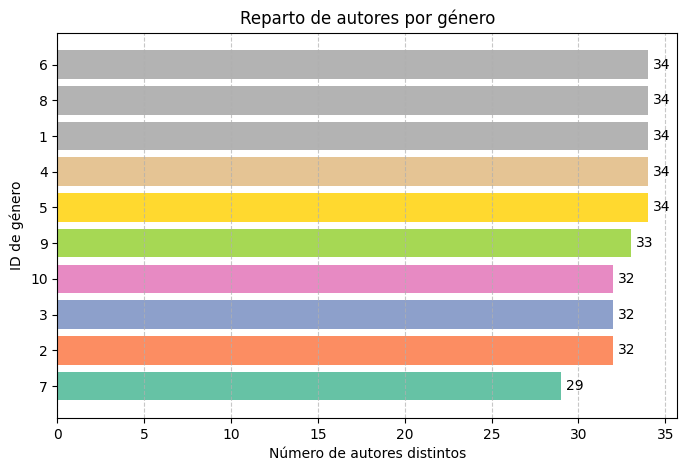

In [ ]:
# Reparto de autores por género

autores_por_genero = (
    df_cancion
    .groupby('id_genero')['id_autor']
    .nunique()
    .reset_index(name='num_autores')
    .sort_values('num_autores')
)

colores = plt.cm.Set2(range(len(autores_por_genero)))

plt.figure(figsize=(8, 5))

plt.barh(
    autores_por_genero['id_genero'].astype(str),
    autores_por_genero['num_autores'],
    color=colores
)

plt.title('Reparto de autores por género')
plt.xlabel('Número de autores distintos')
plt.ylabel('ID de género')
plt.grid(axis='x', linestyle='--', alpha=0.7)

for i, valor in enumerate(autores_por_genero['num_autores']):
    plt.text(
        valor + 0.3,
        i,
        str(valor),
        va='center'
    )

plt.show()

El análisis de `id_autor` muestra que la mayoría de autores aparecen asociados a un único género dentro del dataset.
Esto indica que `id_autor` podría tener una relación muy directa con `id_genero`.

### 6.6 Análisis de la variable id_discografica

In [ ]:
# Análisis de la variable id_discografica frente al género

discografica_genero = (
    df_cancion
    .groupby('id_discografica', dropna=False)
    .agg(
        num_canciones=('id_cancion', 'count'),
        generos_distintos=('id_genero', 'nunique'),
        generos=('id_genero', lambda x: sorted(x.unique()))
    )
    .sort_values(['generos_distintos', 'num_canciones'], ascending=[False, False])
)

total_registros = len(df_cancion)
discograficas_distintas = df_cancion['id_discografica'].nunique(dropna=False)
discograficas_un_genero = (discografica_genero['generos_distintos'] == 1).sum()
discograficas_varios_generos = (discografica_genero['generos_distintos'] > 1).sum()
discograficas_una_cancion = (discografica_genero['num_canciones'] == 1).sum()
media_canciones_por_discografica = discografica_genero['num_canciones'].mean()
porcentaje_un_genero = (discograficas_un_genero / discograficas_distintas) * 100

print(f"Número total de registros: {total_registros}")
print(f"Número de discográficas distintas: {discograficas_distintas}")
print(f"Media de canciones por discográfica: {media_canciones_por_discografica:.2f}")
print(f"Número de discográficas con una sola canción: {discograficas_una_cancion}")
print(f"Número de discográficas asociadas a un único género: {discograficas_un_genero}")
print(f"Número de discográficas asociadas a varios géneros: {discograficas_varios_generos}")
print(f"Porcentaje de discográficas asociadas a un único género: {porcentaje_un_genero:.2f}%")

display(discografica_genero)

Número total de registros: 1000
Número de discográficas distintas: 32
Media de canciones por discográfica: 31.25
Número de discográficas con una sola canción: 0
Número de discográficas asociadas a un único género: 0
Número de discográficas asociadas a varios géneros: 32
Porcentaje de discográficas asociadas a un único género: 0.00%


,num_canciones,generos_distintos,generos
id_discografica,,,
3,80,10,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]"
22,41,10,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]"
19,40,10,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]"
1,38,10,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]"
11,38,10,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]"
9,34,10,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]"
27,34,10,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]"
7,33,10,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]"
17,31,10,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]"


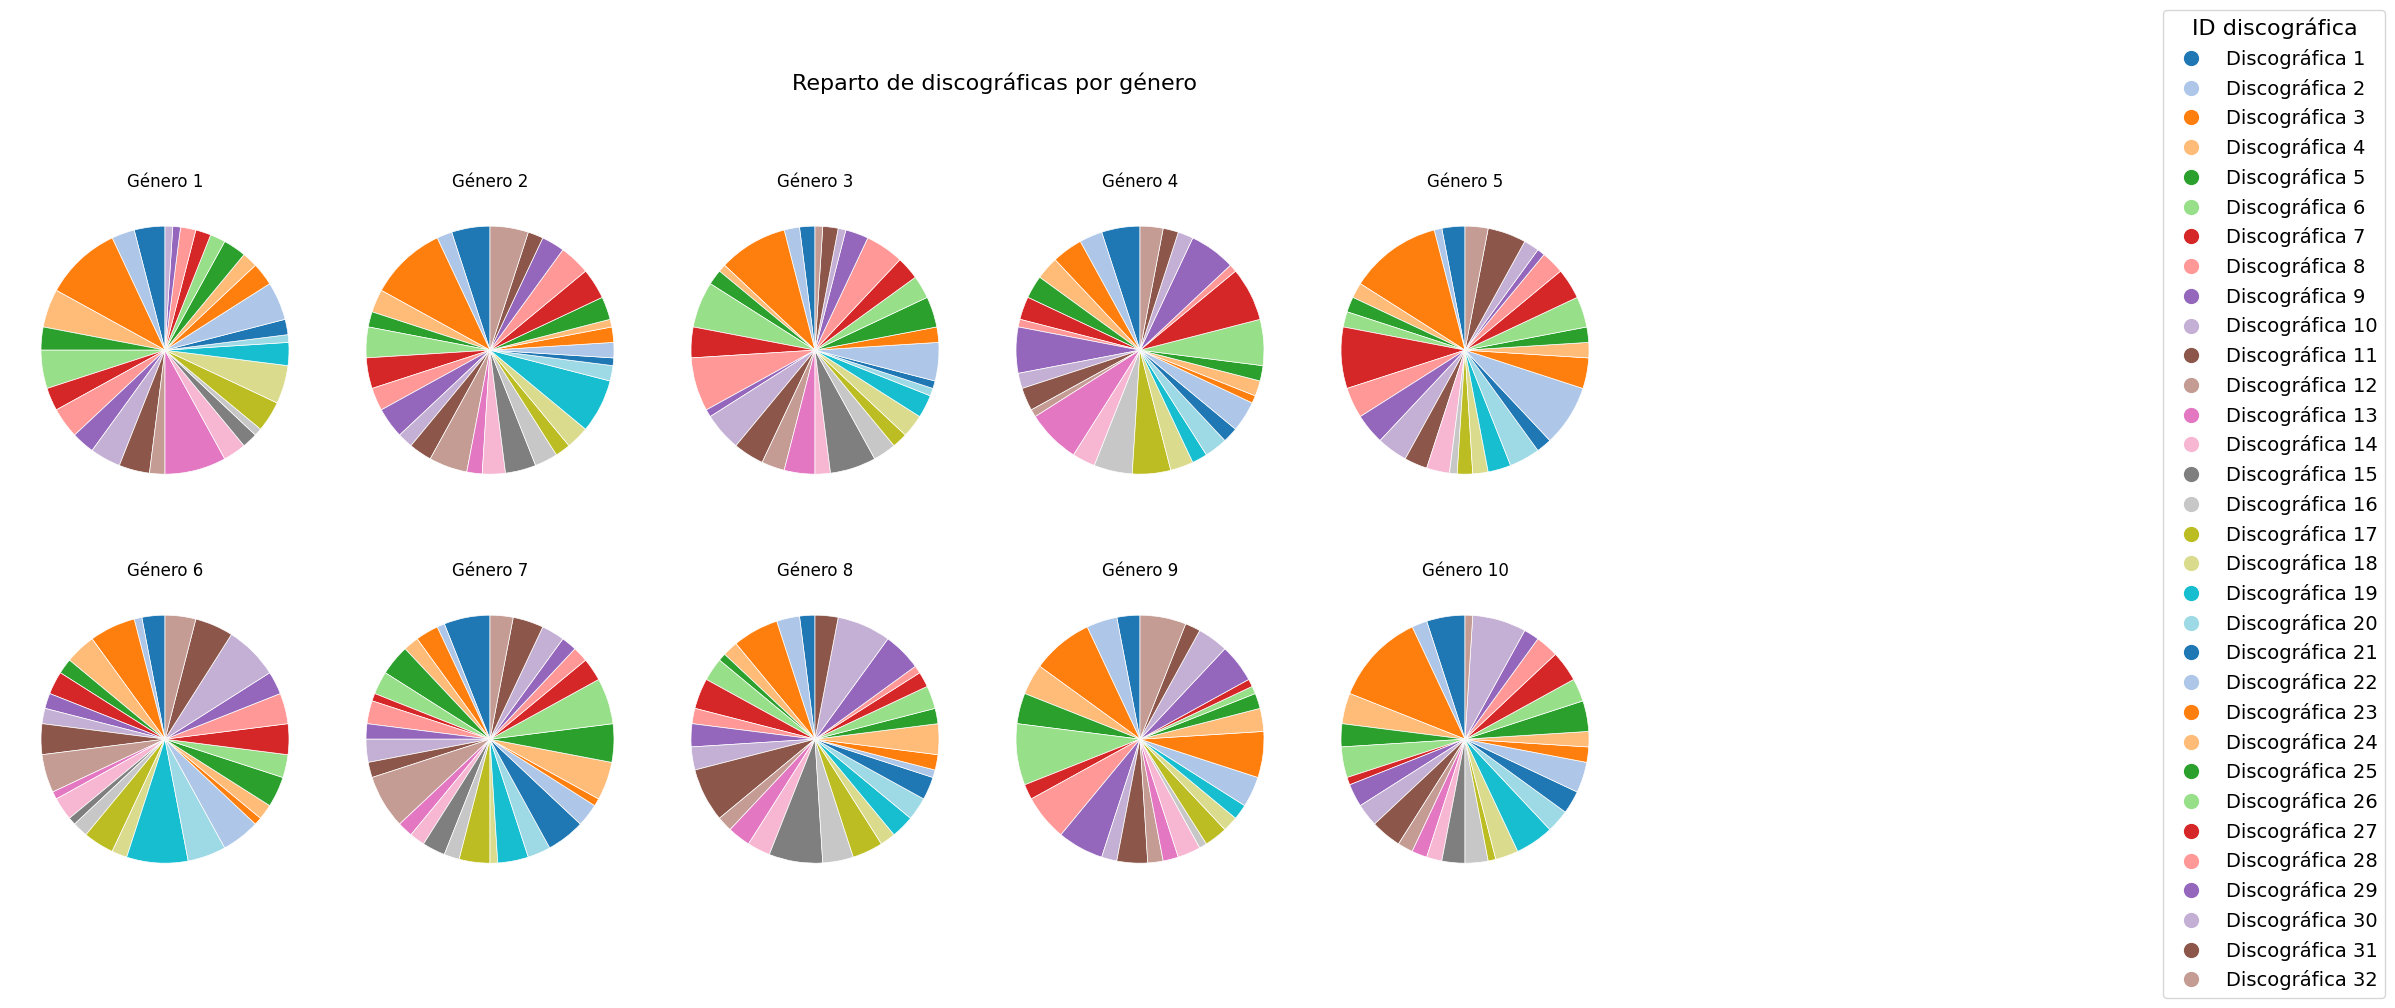

In [ ]:
# Gráficos de tarta: reparto de discográficas dentro de cada género
# Versión más limpia: sin etiquetas en cada tarta y con leyenda común

tabla_genero_discografica = pd.crosstab(
    df_cancion['id_genero'],
    df_cancion['id_discografica']
)

generos = sorted(df_cancion['id_genero'].unique())
discograficas = sorted(df_cancion['id_discografica'].unique())

colores = plt.cm.tab20.colors
color_map = {
    discografica: colores[i % len(colores)]
    for i, discografica in enumerate(discograficas)
}

fig, axes = plt.subplots(2, 5, figsize=(20, 9))
axes = axes.flatten()

for i, genero in enumerate(generos):
    datos_genero = tabla_genero_discografica.loc[genero]
    datos_genero = datos_genero[datos_genero > 0]

    axes[i].pie(
        datos_genero.values,
        startangle=90,
        colors=[color_map[discografica] for discografica in datos_genero.index],
        wedgeprops={'edgecolor': 'white', 'linewidth': 0.5}
    )

    axes[i].set_title(f'Género {genero}')

# Leyenda común para todas las discográficas
handles = [
    plt.Line2D(
        [0],
        [0],
        marker='o',
        color='w',
        label=f'Discográfica {discografica}',
        markerfacecolor=color_map[discografica],
        markersize=12
    )
    for discografica in discograficas
]


fig.legend(
    handles=handles,
    title='ID discográfica',
    loc='center right',
    bbox_to_anchor=(1.20, 0.5),
    fontsize=14,
    title_fontsize=16,
    ncol=1
)

plt.suptitle('Reparto de discográficas por género', fontsize=16)

plt.tight_layout(rect=[0, 0, 0.82, 0.95])

plt.show()


Se observa que las discográficas aparecen bastante repartidas entre los distintos géneros. No se aprecia que una única discográfica concentre claramente la mayoría de canciones de algún género concreto, sino que en cada género participan varias discográficas.



El análisis de las variables categóricas codificadas muestra que `id_disco` e `id_autor` presentan un número de valores únicos elevado en relación con el tamaño del dataset. Además, ambas variables muestran una relación muy directa con `id_genero`.

En cambio, `id_discografica` presenta un número de valores únicos más moderado y no aparece asociada directamente a un único género.

## 7. Correlaciones entre variables

### 7.1 Matriz de correlación general

In [ ]:
variables_correlacion = [
    'id_genero',
    'id_cancion',
    'coste',
    'duracion',
    'id_disco',
    'id_autor',
    'id_discografica'
]

matriz_correlacion = df_cancion[variables_correlacion].corr()

display(matriz_correlacion)

,id_genero,id_cancion,coste,duracion,id_disco,id_autor,id_discografica
id_genero,1.000000,0.994988,-0.024438,0.034154,0.995268,0.949373,0.057148
id_cancion,0.994988,1.000000,-0.019318,0.031791,0.992430,0.946061,0.055397
coste,-0.024438,-0.019318,1.000000,-0.032302,-0.021538,-0.027260,0.008789
duracion,0.034154,0.031791,-0.032302,1.000000,0.038202,0.036501,-0.041067
id_disco,0.995268,0.992430,-0.021538,0.038202,1.000000,0.946262,0.051574
id_autor,0.949373,0.946061,-0.027260,0.036501,0.946262,1.000000,0.067811
id_discografica,0.057148,0.055397,0.008789,-0.041067,0.051574,0.067811,1.000000


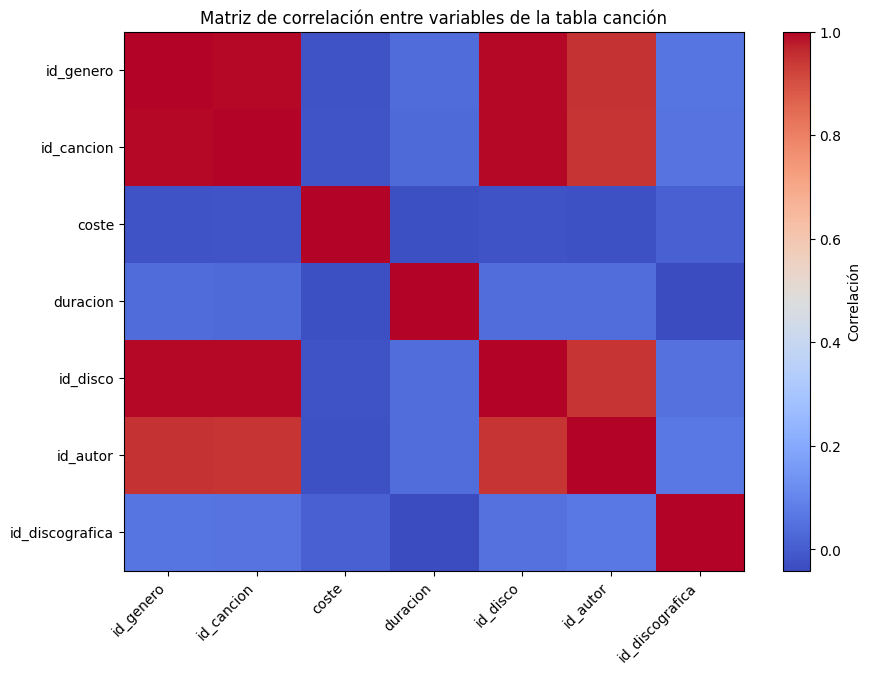

In [ ]:
plt.figure(figsize=(10, 7))

plt.imshow(matriz_correlacion, cmap='coolwarm', aspect='auto')
plt.colorbar(label='Correlación')

plt.xticks(
    range(len(matriz_correlacion.columns)),
    matriz_correlacion.columns,
    rotation=45,
    ha='right'
)

plt.yticks(
    range(len(matriz_correlacion.columns)),
    matriz_correlacion.columns
)

plt.title('Matriz de correlación entre variables de la tabla canción')

plt.show()

In [ ]:
correlacion_con_genero = (
    matriz_correlacion['id_genero']
    .drop('id_genero')
    .sort_values(ascending=False)
)

display(correlacion_con_genero)

,id_genero
id_disco,0.995268
id_cancion,0.994988
id_autor,0.949373
id_discografica,0.057148
duracion,0.034154
coste,-0.024438




La matriz de correlación permite observar la relación lineal entre las variables numéricas y las variables codificadas de la tabla `cancion`.

En las variables numéricas reales, como `duracion` y `coste`, no se observan correlaciones fuertes con `id_genero`. Esto indica que, de forma individual, estas variables no separan claramente los géneros.

En cambio, variables codificadas como `id_disco`, `id_autor` e `id_cancion` muestran correlaciones elevadas con `id_genero`.

## 8. Cierre del análisis preliminar
Tras el análisis realizado, se mantiene `id_genero` como variable objetivo del problema, ya que representa el género musical codificado.

El resto de variables de la tabla `cancion` quedan documentadas como posibles variables de entrada para fases posteriores de Machine Learning. En este notebook no se realiza una selección definitiva, sino que se analizan sus características, incidencias y relaciones con la variable objetivo.

En conjunto, este análisis permite dejar documentado el comportamiento de todas las variables disponibles antes de la fase de Machine Learning. Las variables numéricas `duracion` y `coste` aportan información cuantitativa, mientras que `id_disco`, `id_autor` e `id_discografica` representan variables categóricas codificadas. Además, `cancion` se analiza como variable textual e `id_cancion` como identificador único de cada registro.
